# Лабораторна робота № 3
## Діагностика шкал вимірювання

Курс СК26 «Інтелектуальний аналіз та візуалізація даних»

**Тривалість:** 2 год аудиторно + 3 год самостійно · **Оцінка:** 4 бали
**Файли:** `Ковід_дані_навчальні.xlsx`, `ЛР3_помилковий_аналіз.ipynb`

---

Шкала вимірювання визначає, які операції над змінною взагалі мають сенс.
Комп'ютер цього не знає: він порахує середнє від номера телефону й не поскаржиться.
Знати має вимірювач.

У цій роботі ви складаєте **паспорт восьми змінних** свого варіанта, показуєте на
власних даних, які статистики для них недопустимі, і виправляєте чужий аналіз,
де таких помилок десять.

In [1]:
ПРІЗВИЩЕ_ІМЯ = 'Кузнєцов Макар'      # напишіть тут своє прізвище та ім'я
ГРУПА        = 'ШІ-32'
НОМЕР        = 8       # ваш номер за списком групи (1–30)

assert ПРІЗВИЩЕ_ІМЯ and ГРУПА and НОМЕР, 'Заповніть три поля вище'
assert 1 <= НОМЕР <= 30, 'Номер має бути від 1 до 30'

In [2]:
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_colwidth', 60)

ВАРІАНТИ = json.load(open('lr3_variants_student.json'))
В = ВАРІАНТИ[НОМЕР - 1]

print('=' * 74)
print(f'ВАРІАНТ {В["варіант"]}   ·   {ПРІЗВИЩЕ_ІМЯ}   ·   {ГРУПА}')
print('=' * 74)
print()
print('Ваші вісім стовпців:')
for i, c in enumerate(В['стовпці'], 1):
    print(f'   {i}. {c}')
print()
print('Ваша пара для аналізу зв’язку:', ' та '.join(В['пара']))
print()
print('Ваше додаткове питання:')
print('  ', В['питання'])

ВАРІАНТ 8   ·   Кузнєцов Макар   ·   ШІ-32

Ваші вісім стовпців:
   1. Телефон
   2. Примітка
   3. ступінь КТ
   4. Дата розтину
   5. Ліжко днів
   6. Гемогл1
   7. АЛАТ1
   8. БР заг1

Ваша пара для аналізу зв’язку: Гемогл1 та Гематокрит1

Ваше додаткове питання:
   Знайдіть у файлі стовпець, де одна й та сама величина записана у двох несумісних кодуваннях. Скільки спостережень втратить наївне обчислення середнього?


In [3]:
ФАЙЛ = 'Ковід_дані_навчальні.xlsx'
df = pd.read_excel(ФАЙЛ, sheet_name='Лист1', engine='openpyxl')
МОЇ = В['стовпці']

print('Розмір набору:', df.shape)
df[МОЇ].head(8)

Розмір набору: (121, 77)


,Телефон,Примітка,ступінь КТ,Дата розтину,Ліжко днів,Гемогл1,АЛАТ1,БР заг1
0,0958469788 дружина Ганна,NaN,сердній,2022-03-11,14,157,52.4,15.3
1,"0671778486, 0994887663 дружина Оксана","отримував актемра, часті носові кровотечі, втрата нюху",середній,NaT,22,145,22.0,61.8
2,"0958768045, чоловік Степан 0951784726",часта втрата свідомосі в стаціонарі,критичний,NaT,20,137,21.9,11.7
3,0959819331. дочка Валентина 0960845205,панкреонекроз,критичний,NaT,20,87,38.7,11.9
4,"0952294866, дочка Дарина 0678360161",NaN,NaN,NaT,27,126,97.7,13.6
5,0959922983 сестра Софія,NaN,середній,2021-12-26,9(5 у реан),134,112.0,11.9
6,"0998073702, дружина Наталія 0998382226","глюкозурія, кетонові тіла в сечі, ЦД, фібриляція передс",важкий,NaT,18,151,60.4,15.3
7,"0637258771, син Сергій 0968413301",NaN,легкий,NaT,10,130,54.3,13.6


---
# Етап 1. Паспорт змінних

Для кожного з восьми стовпців визначте шкалу вимірювання. Спирайтеся не на тип даних
у pandas, а на **зміст величини**: що означають її значення і які порівняння між ними
мають сенс.

Нагадування:

| Шкала | Ознака |
|---|---|
| Номінальна | значення можна лише порівняти на рівність |
| Порядкова | є природний порядок, але відстані між сусідніми рівнями невідомі |
| Інтервальна | різниці мають сенс, нуль умовний |
| Відношень | є природний нуль, відношення мають сенс |
| Абсолютна | природні і нуль, і одиниця вимірювання |

Окремо позначайте **ідентифікатори** — значення, що не є величиною взагалі
(номер історії хвороби, прізвище, телефон).

In [4]:
# Спершу подивіться, що каже pandas — і не довіряйте йому
df[МОЇ].info()

<class 'pandas.DataFrame'>
RangeIndex: 121 entries, 0 to 120
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   Телефон       120 non-null    object        
 1   Примітка      45 non-null     str           
 2   ступінь КТ    42 non-null     str           
 3   Дата розтину  61 non-null     datetime64[us]
 4   Ліжко днів    120 non-null    object        
 5   Гемогл1       119 non-null    object        
 6   АЛАТ1         115 non-null    float64       
 7   БР заг1       110 non-null    float64       
dtypes: datetime64[us](1), float64(2), object(3), str(2)
memory usage: 7.7+ KB


In [5]:
# Далі — що є всередині насправді
for c in МОЇ:
    з = df[c].dropna()
    типи = ', '.join(f'{t.__name__}×{n}' for t, n in з.map(type).value_counts().items())
    print(f'--- {c}')
    print(f'    непорожніх {len(з)} з {len(df)} | унікальних {з.nunique()} | типи: {типи}')
    print(f'    приклади: {[repr(v) for v in з.unique()[:4]]}')
    print()

--- Телефон
    непорожніх 120 з 121 | унікальних 120 | типи: str×97, int×23
    приклади: ["'0958469788 дружина Ганна'", "'0671778486, 0994887663 дружина Оксана'", "'0958768045, чоловік Степан 0951784726'", "'0959819331. дочка Валентина 0960845205'"]

--- Примітка
    непорожніх 45 з 121 | унікальних 44 | типи: str×45
    приклади: ["'отримував актемра, часті носові кровотечі, втрата нюху'", "'часта втрата свідомосі в стаціонарі'", "'панкреонекроз'", "'глюкозурія, кетонові тіла в сечі, ЦД, фібриляція передс'"]

--- ступінь КТ
    непорожніх 42 з 121 | унікальних 12 | типи: str×42
    приклади: ["'сердній'", "'середній'", "'критичний'", "'важкий'"]

--- Дата розтину
    непорожніх 61 з 121 | унікальних 50 | типи: Timestamp×61
    приклади: ["Timestamp('2022-03-11 00:00:00')", "Timestamp('2021-12-26 00:00:00')", "Timestamp('2021-11-19 00:00:00')", "Timestamp('2022-05-13 00:00:00')"]

--- Ліжко днів
    непорожніх 120 з 121 | унікальних 40 | типи: int×119, str×1
    приклади: ['14', '22'

### Заповніть паспорт

Для кожного стовпця вкажіть шкалу та **обґрунтування** — одне речення про те,
чому саме ця шкала. Обґрунтування оцінюється, назва шкали сама по собі — ні.

In [6]:
ПАСПОРТ = {
    'Телефон': ('ідентифікатор',
        'Це контакт родичів пацієнта (номер плюс приписка «дружина Ганна»), а не величина: '
        'середнє чи різниця двох номерів нічого не означають.'),
    'Примітка': ('номінальна',
        'Вільний текстовий коментар лікаря: записи можна лише порівняти на збіг, порядку між ними '
        'немає, і майже кожен унікальний (44 різні з 45).'),
    'ступінь КТ': ('порядкова',
        'Рівні «легкий < середній < важкий < вкрай важкий < критичний» мають природний порядок '
        'тяжкості, але відстані між сусідніми ступенями невідомі.'),
    'Дата розтину': ('інтервальна',
        'Календарна дата: різниця двох дат у днях має сенс, а нуль (Різдво Христове чи 1970-01-01) '
        'умовний, тому «вдвічі пізніша дата» — безглуздя.'),
    'Ліжко днів': ('відношень',
        'Тривалість перебування в днях: є природний нуль, 20 днів справді вдвічі довше за 10, '
        'а одиницю обрано умовно (можна рахувати в годинах).'),
    'Гемогл1': ('відношень',
        'Концентрація гемоглобіну в г/л: нуль означає повну відсутність гемоглобіну, тому 140 г/л '
        'удвічі більше за 70 г/л; одиниця умовна (г/л чи г/дл).'),
    'АЛАТ1': ('відношень',
        'Активність ферменту АЛТ в Од/л має абсолютний нуль, а відношення «утричі вище норми» '
        'змістовне й клінічно вживане.'),
    'БР заг1': ('відношень',
        'Концентрація загального білірубіну в мкмоль/л: природний нуль, відношення мають сенс, '
        'одиниця умовна (можна перевести в мг/дл).'),
}

for c in МОЇ:
    ПАСПОРТ.setdefault(c, ('', ''))

паспорт_df = pd.DataFrame(
    [(c, ПАСПОРТ[c][0], ПАСПОРТ[c][1]) for c in МОЇ],
    columns=['Стовпець', 'Шкала', 'Обґрунтування'])
with pd.option_context('display.max_colwidth', None):   # шаблон обрізає текст до 60 символів
    display(паспорт_df)

,Стовпець,Шкала,Обґрунтування
0,Телефон,ідентифікатор,"Це контакт родичів пацієнта (номер плюс приписка «дружина Ганна»), а не величина: середнє чи різниця двох номерів нічого не означають."
1,Примітка,номінальна,"Вільний текстовий коментар лікаря: записи можна лише порівняти на збіг, порядку між ними немає, і майже кожен унікальний (44 різні з 45)."
2,ступінь КТ,порядкова,"Рівні «легкий < середній < важкий < вкрай важкий < критичний» мають природний порядок тяжкості, але відстані між сусідніми ступенями невідомі."
3,Дата розтину,інтервальна,"Календарна дата: різниця двох дат у днях має сенс, а нуль (Різдво Христове чи 1970-01-01) умовний, тому «вдвічі пізніша дата» — безглуздя."
4,Ліжко днів,відношень,"Тривалість перебування в днях: є природний нуль, 20 днів справді вдвічі довше за 10, а одиницю обрано умовно (можна рахувати в годинах)."
5,Гемогл1,відношень,"Концентрація гемоглобіну в г/л: нуль означає повну відсутність гемоглобіну, тому 140 г/л удвічі більше за 70 г/л; одиниця умовна (г/л чи г/дл)."
6,АЛАТ1,відношень,"Активність ферменту АЛТ в Од/л має абсолютний нуль, а відношення «утричі вище норми» змістовне й клінічно вживане."
7,БР заг1,відношень,"Концентрація загального білірубіну в мкмоль/л: природний нуль, відношення мають сенс, одиниця умовна (можна перевести в мг/дл)."


In [7]:
# --- САМОПЕРЕВІРКА 1 ---
ДОПУСТИМІ = {'номінальна', 'порядкова', 'інтервальна', 'відношень',
             'абсолютна', 'ідентифікатор'}
for c in МОЇ:
    ш, об = ПАСПОРТ[c]
    assert ш.strip().lower() in ДОПУСТИМІ, f'{c}: шкалу «{ш}» не розпізнано'
    assert len(об.strip()) >= 25, f'{c}: обґрунтування закоротке'
print('Самоперевірка 1 пройдена: усі вісім стовпців мають шкалу та обґрунтування.')

Самоперевірка 1 пройдена: усі вісім стовпців мають шкалу та обґрунтування.


---
# Етап 2. Допустимі статистики

Для кожного стовпця обчисліть **тільки те, що дозволяє його шкала**.

* номінальна та ідентифікатор — мода, частоти
* порядкова — додатково медіана та квантилі
* інтервальна — додатково середнє та стандартне відхилення
* відношень і абсолютна — усе, зокрема коефіцієнт варіації

Якщо для стовпця не можна порахувати нічого, крім частот, — так і напишіть.

In [8]:
# «ступінь КТ» записано дванадцятьма способами: синоніми, одруківки, пробіли в кінці.
# Порядок рівнів задаю явно — алфавітний порядок тут хибний.
ПОРЯДОК_КТ = ['легкий', 'середній', 'важкий', 'вкрай важкий', 'критичний']
СИНОНІМИ_КТ = {'легка': 'легкий', 'сердній': 'середній',
               'серед ступ': 'середній', 'серед ступеня': 'середній'}


def очистити_ступінь(s):
    s = s.astype('string').str.strip().replace(СИНОНІМИ_КТ)
    return pd.Series(pd.Categorical(s, categories=ПОРЯДОК_КТ, ordered=True), index=s.index)


def допустима_статистика(стовпець, шкала):
    """Повертає словник статистик, дозволених для цієї шкали."""
    з = df[стовпець].dropna()
    р = {'непорожніх': len(з), 'унікальних': з.nunique()}
    ш = шкала.strip().lower()

    if ш in ('ідентифікатор',):
        return р

    # приведення до «чистих» значень відповідно до шкали
    if ш == 'порядкова':
        з = очистити_ступінь(з).dropna()
        р['унікальних після чистки'] = з.nunique()
    elif ш in ('відношень', 'абсолютна'):
        числа = pd.to_numeric(з, errors='coerce')
        р['відкинуто не-чисел'] = list(з[числа.isna()])
        з = числа.dropna()

    # мода й частоти — для всіх шкал
    частоти = з.value_counts()
    р['мода'] = частоти.index[0]
    р['частота моди'] = int(частоти.iloc[0])
    if з.nunique() <= 10:
        р['частоти'] = частоти.sort_index().to_dict() if ш == 'порядкова' else частоти.to_dict()
    if ш == 'номінальна':
        return р

    # порядкова — медіана та квартилі (по рангах, без інтерполяції між рівнями)
    if ш == 'порядкова':
        q = з.cat.codes.quantile([.25, .5, .75], interpolation='lower')
        р['Q1'], р['медіана'], р['Q3'] = (з.cat.categories[int(k)] for k in q)
        return р

    if ш == 'інтервальна':                       # дати
        р['медіана'] = з.median().date()
        р['мін'], р['макс'] = з.min().date(), з.max().date()
        р['середнє'] = з.mean().date()
        р['ст. відхилення, днів'] = round(з.std() / pd.Timedelta(days=1), 1)
        return р                                 # коефіцієнт варіації недопустимий

    # відношень / абсолютна
    р['мін'], р['макс'] = з.min(), з.max()
    р['Q1'], р['медіана'], р['Q3'] = (round(v, 2) for v in з.quantile([.25, .5, .75]))
    р['середнє'] = round(з.mean(), 2)
    р['ст. відхилення'] = round(з.std(), 2)
    р['коеф. варіації, %'] = round(100 * з.std() / з.mean(), 1)
    return р


for c in МОЇ:
    print(f'--- {c}  ({ПАСПОРТ[c][0]})')
    print('   ', допустима_статистика(c, ПАСПОРТ[c][0]))
    print()

--- Телефон  (ідентифікатор)
    {'непорожніх': 120, 'унікальних': 120}

--- Примітка  (номінальна)
    {'непорожніх': 45, 'унікальних': 44, 'мода': 'Поліалергетик', 'частота моди': 2}

--- ступінь КТ  (порядкова)
    {'непорожніх': 42, 'унікальних': 12, 'унікальних після чистки': 5, 'мода': 'середній', 'частота моди': 18, 'частоти': {'легкий': 7, 'середній': 18, 'важкий': 10, 'вкрай важкий': 4, 'критичний': 3}, 'Q1': 'середній', 'медіана': 'середній', 'Q3': 'важкий'}

--- Дата розтину  (інтервальна)
    {'непорожніх': 61, 'унікальних': 50, 'мода': Timestamp('2022-06-07 00:00:00'), 'частота моди': 3, 'медіана': datetime.date(2022, 4, 23), 'мін': datetime.date(2021, 1, 6), 'макс': datetime.date(2022, 6, 22), 'середнє': datetime.date(2022, 4, 6), 'ст. відхилення, днів': 72.6}

--- Ліжко днів  (відношень)
    {'непорожніх': 120, 'унікальних': 40, 'відкинуто не-чисел': ['9(5 у реан)'], 'мода': np.float64(10.0), 'частота моди': 12, 'мін': np.float64(1.0), 'макс': np.float64(79.0), 'Q1': 10.

---
# Етап 3. Три безглузді числа

`df.describe()` порахує статистики для всього, що схоже на число. Частина цих чисел
не має жодного змісту.

Знайдіть **щонайменше три** такі числа у своєму наборі: обчисліть їх, а потім
поясніть, чому кожне з них безглузде.

In [9]:
df[МОЇ].describe(include='all').T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
Телефон,120,120,0958469788 дружина Ганна,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Примітка,45,44,Поліалергетик,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ступінь КТ,42,12,середній,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Дата розтину,61,NaN,NaN,NaN,2022-04-06 13:22:37.377049,2021-01-06 00:00:00,2022-03-29 00:00:00,2022-04-23 00:00:00,2022-05-07 00:00:00,2022-06-22 00:00:00,NaN
Ліжко днів,120.0,40.0,10.0,12.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Гемогл1,119.0,64.0,134.0,6.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
АЛАТ1,115.0,NaN,NaN,NaN,40.643826,0.6,13.0,37.4,60.3,138.0,32.210484
БР заг1,110.0,NaN,NaN,NaN,17.295273,7.43,13.6,15.3,18.3,84.0,10.486351


In [10]:
# 1) Середнє «числових» телефонів: 23 номери Excel зберіг як int і з'їв провідний нуль
тел_числа = df['Телефон'][df['Телефон'].map(lambda v: isinstance(v, int))]
середній_телефон = тел_числа.mean()

# 2) Середній «ступінь КТ», якщо закодувати рівні так, як це зробить pandas (за алфавітом)
алф = df['ступінь КТ'].dropna().astype('category')
середній_код_кт = алф.cat.codes.mean()

# 3) Коефіцієнт варіації дат розтину (дні від 1970-01-01)
дні_розтину = df['Дата розтину'].dropna().astype('int64') / 86400e9
cv_розтину = 100 * дні_розтину.std() / дні_розтину.mean()

# 4) describe() каже, що в «ступінь КТ» 12 унікальних значень
унікальних_кт = df['ступінь КТ'].nunique()

БЕЗГЛУЗДІ = [
    ('Телефон', 'середнє', round(середній_телефон),
     'Номер телефону — ідентифікатор: «середній номер» не належить нікому, '
     'а 23 «числові» номери ще й без провідного нуля.'),
    ('ступінь КТ', 'середнє алфавітних кодів', round(середній_код_кт, 2),
     f'Коди 0…{len(алф.cat.categories) - 1} присвоєно за алфавітом («важкий»=0, «середній»=11), '
     'тож число не відображає тяжкість; до того ж ступінь — порядкова шкала, середнє для неї недопустиме.'),
    ('Дата розтину', 'коефіцієнт варіації, %', round(cv_розтину, 3),
     'Дата — інтервальна шкала з умовним нулем (1970-01-01); зсув початку відліку змінить CV '
     'як завгодно, тож «0.4%» не означає жодної однорідності.'),
    ('ступінь КТ', 'кількість унікальних (describe)', унікальних_кт,
     'Насправді рівнів п’ять: решта — одруківки й пробіли («сердній», «серед ступ», «важкий »), '
     'тож це число міряє неохайність введення, а не різноманіття тяжкості.'),
]

assert len(БЕЗГЛУЗДІ) >= 3, 'Потрібно щонайменше три приклади'
with pd.option_context('display.max_colwidth', None):   # шаблон обрізає текст до 60 символів
    display(pd.DataFrame([(с, ст, f'{з:g}', ч) for с, ст, з, ч in БЕЗГЛУЗДІ],
                         columns=['Стовпець', 'Статистика', 'Значення', 'Чому безглузде']))

,Стовпець,Статистика,Значення,Чому безглузде
0,Телефон,середнє,7.58799e+08,"Номер телефону — ідентифікатор: «середній номер» не належить нікому, а 23 «числові» номери ще й без провідного нуля."
1,ступінь КТ,середнє алфавітних кодів,5.9,"Коди 0…11 присвоєно за алфавітом («важкий»=0, «середній»=11), тож число не відображає тяжкість; до того ж ступінь — порядкова шкала, середнє для неї недопустиме."
2,Дата розтину,"коефіцієнт варіації, %",0.38,"Дата — інтервальна шкала з умовним нулем (1970-01-01); зсув початку відліку змінить CV як завгодно, тож «0.4%» не означає жодної однорідності."
3,ступінь КТ,кількість унікальних (describe),12,"Насправді рівнів п’ять: решта — одруківки й пробіли («сердній», «серед ступ», «важкий »), тож це число міряє неохайність введення, а не різноманіття тяжкості."


---
# Етап 4. Міра зв'язку для вашої пари

Для двох змінних вашого варіанта треба оцінити зв'язок. Міру обирає **пара шкал**,
а не зручність:

| Поєднання шкал | Міра |
|---|---|
| відношень × відношень | кореляція Пірсона |
| порядкова × порядкова | рангова кореляція Спірмена |
| номінальна × номінальна | χ² та коефіцієнт Крамера (V) |
| відношень × бінарна номінальна | точковий бісеріальний коефіцієнт |
| номінальна × порядкова | коефіцієнт Крамера (V) |

Обґрунтуйте вибір, обчисліть міру й поясніть результат. Окремо покажіть, **що
станеться**, якщо застосувати Пірсона там, де він недопустимий, — і чому отримане
число не можна інтерпретувати.

In [11]:
A, B = В['пара']
print('Ваша пара:', A, '×', B)
print()
print(f'{A}: шкала —', ПАСПОРТ.get(A, ('не у вашому списку',))[0] or '(визначте самостійно)')
print(f'{B}: шкала —', ПАСПОРТ.get(B, ('не у вашому списку',))[0] or '(визначте самостійно)')
print()
print(df[[A, B]].head(6).to_string())

Ваша пара: Гемогл1 × Гематокрит1

Гемогл1: шкала — відношень
Гематокрит1: шкала — не у вашому списку

  Гемогл1  Гематокрит1
0     157         48.0
1     145         42.2
2     137         40.0
3      87         22.0
4     126         40.0
5     134         39.0


Спостережень з обома значеннями: 114 з 121
Пірсон  r   = 0.781   (p = 1.3e-24)
Спірмен rho = 0.727   (p = 5.5e-20)


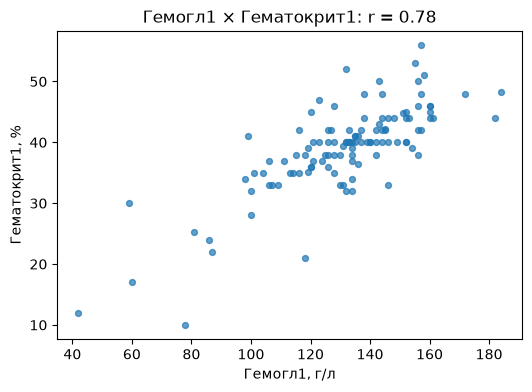

In [12]:
ОБРАНА_МІРА = 'кореляція Пірсона (з перевіркою Спірменом)'
ЧОМУ_САМЕ_ВОНА = ('Гемоглобін (г/л) і гематокрит (%) — обидві величини у шкалі відношень, '
                  'а фізіологічно гематокрит приблизно пропорційний гемоглобіну, тож очікуємо '
                  'лінійний зв’язок. Спірмена рахую як контроль стійкості до викидів.')

assert ОБРАНА_МІРА and len(ЧОМУ_САМЕ_ВОНА) >= 40, 'Заповніть обидва поля'

from scipy import stats

пара = pd.DataFrame({A: pd.to_numeric(df[A], errors='coerce'),
                     B: pd.to_numeric(df[B], errors='coerce')}).dropna()
r_p, p_p = stats.pearsonr(пара[A], пара[B])
r_s, p_s = stats.spearmanr(пара[A], пара[B])

print(f'Спостережень з обома значеннями: {len(пара)} з {len(df)}')
print(f'Пірсон  r   = {r_p:.3f}   (p = {p_p:.1e})')
print(f'Спірмен rho = {r_s:.3f}   (p = {p_s:.1e})')

fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(пара[A], пара[B], s=18, alpha=.7)
ax.set_xlabel(f'{A}, г/л'); ax.set_ylabel(f'{B}, %')
ax.set_title(f'{A} × {B}: r = {r_p:.2f}')
plt.show()

In [13]:
# Тепер — контрприклад: застосуйте кореляцію Пірсона незалежно від шкал
# і поясніть, чому отримане число не можна використовувати.

гем = pd.to_numeric(df['Гемогл1'], errors='coerce')
сирий = df['ступінь КТ'].dropna()
чистий_кт = очистити_ступінь(сирий)

# Три однаково «законні» кодування одного й того самого порядкового стовпця
кодування = {
    'алфавітні коди pandas (0…11)':     сирий.astype('category').cat.codes,
    'правильний порядок, 1-2-3-4-5':     чистий_кт.cat.codes + 1,
    'той самий порядок, 1-2-4-8-16':     2 ** чистий_кт.cat.codes,
}
for назва, коди in кодування.items():
    m = гем[коди.index].notna()
    r = stats.pearsonr(коди[m], гем[коди.index][m])[0]
    rho = stats.spearmanr(коди[m], гем[коди.index][m])[0]
    print(f'{назва:34s}  Пірсон r = {r:+.3f}   Спірмен = {rho:+.3f}')

тел = df['Телефон'][df['Телефон'].map(lambda v: isinstance(v, int))].astype(float)
тел = тел[гем[тел.index].notna()]
print()
print(f'Пірсон «Телефон × Гемогл1» (n={len(тел)}): r = {stats.pearsonr(тел, гем[тел.index])[0]:+.3f}')

алфавітні коди pandas (0…11)        Пірсон r = +0.183   Спірмен = +0.169
правильний порядок, 1-2-3-4-5       Пірсон r = -0.164   Спірмен = -0.003
той самий порядок, 1-2-4-8-16       Пірсон r = -0.265   Спірмен = -0.003

Пірсон «Телефон × Гемогл1» (n=23): r = +0.014


**Висновок етапу 4.** Гемоглобін і гематокрит пов’язані сильно й позитивно: Пірсон r ≈ 0.78,
Спірмен ≈ 0.73, обидва з p ≪ 0.001 на 114 пацієнтах. Це очікувано: гематокрит — частка об’єму
крові, яку займають еритроцити, а гемоглобін міститься саме в них. Спірмен трохи нижчий через
кілька пар, що випадають із прямої (наприклад, Hb 118 г/л при Hct 21% — схоже на помилку введення).

**Контрприклад.** Для порядкового «ступеня КТ» Пірсон залежить від того, якими числами ми
довільно позначили рівні: алфавітні коди, коди 1-5 і коди 1-2-4-8-16 дають *різні* r, хоча
інформація однакова (−0.16 проти −0.27), і обидва створюють видимість зв’язку. Спірмен для двох правильних кодувань однаковий (≈ 0, зв’язку немає), бо залежить лише від
порядку. Алфавітне кодування ламає навіть порядок, тож там хибні обидві міри. Пірсон
«телефон × гемоглобін» — просто шум: номер не є величиною, і будь-яке ненульове r тут випадкове.

---
# Етап 5. Підготовка змінних до моделі

Шкала визначає не лише статистику, а й спосіб кодування.

| Шкала | Як готують до моделі |
|---|---|
| Номінальна | one-hot кодування; порядок категорій не вводять |
| Порядкова | впорядкована категорія або цілі коди із **заданим** порядком |
| Інтервальна | стандартизація; для дат — перехід до тривалостей |
| Відношень | нормалізація або стандартизація; можливе логарифмування |
| Ідентифікатор | у модель не беруть узагалі |

Для кожного свого стовпця вкажіть спосіб підготовки — і **виконайте його**
щонайменше для трьох стовпців різних шкал.

In [14]:
ПІДГОТОВКА = {
    'Телефон':      'не беремо в модель — ідентифікатор контакту, не величина',
    'Примітка':     'вільний текст: замість нього бінарна ознака «є примітка» (one-hot), '
                    'за потреби — прапорці ключових слів',
    'ступінь КТ':   'чистимо синоніми й одруківки, впорядкована категорія з кодами 0–4 '
                    'у заданому порядку легкий→критичний',
    'Дата розтину': 'не беремо: є лише в померлих — це витік цільової змінної',
    'Ліжко днів':   'витягуємо число з «9(5 у реан)», log1p через правий хвіст, потім стандартизація',
    'Гемогл1':      'текстові «даних», «гемоліз» → NaN, заповнюємо медіаною, стандартизація',
    'АЛАТ1':        'сильна асиметрія: log1p, потім min-max нормалізація до [0, 1]',
    'БР заг1':      'асиметрія з викидом 84: log1p, потім стандартизація',
}
for c in МОЇ:
    ПІДГОТОВКА.setdefault(c, '')

with pd.option_context('display.max_colwidth', None):   # шаблон обрізає текст до 60 символів
    display(pd.DataFrame([(c, ПАСПОРТ[c][0], ПІДГОТОВКА[c]) for c in МОЇ],
                         columns=['Стовпець', 'Шкала', 'Як готуємо']))

,Стовпець,Шкала,Як готуємо
0,Телефон,ідентифікатор,"не беремо в модель — ідентифікатор контакту, не величина"
1,Примітка,номінальна,"вільний текст: замість нього бінарна ознака «є примітка» (one-hot), за потреби — прапорці ключових слів"
2,ступінь КТ,порядкова,"чистимо синоніми й одруківки, впорядкована категорія з кодами 0–4 у заданому порядку легкий→критичний"
3,Дата розтину,інтервальна,не беремо: є лише в померлих — це витік цільової змінної
4,Ліжко днів,відношень,"витягуємо число з «9(5 у реан)», log1p через правий хвіст, потім стандартизація"
5,Гемогл1,відношень,"текстові «даних», «гемоліз» → NaN, заповнюємо медіаною, стандартизація"
6,АЛАТ1,відношень,"сильна асиметрія: log1p, потім min-max нормалізація до [0, 1]"
7,БР заг1,відношень,"асиметрія з викидом 84: log1p, потім стандартизація"


In [15]:
# ваш код: реалізуйте підготовку для трьох стовпців різних шкал
Х = pd.DataFrame(index=df.index)

# порядкова: коди у заданому порядку, а не за алфавітом
кт = очистити_ступінь(df['ступінь КТ'])
Х['ступінь_КТ_код'] = кт.cat.codes.replace(-1, np.nan)        # -1 = пропуск

# номінальна: one-hot «є примітка»
Х = Х.join(pd.get_dummies(df['Примітка'].notna().map({True: 'є', False: 'нема'}),
                          prefix='примітка', dtype=int))

# відношень: «9(5 у реан)» → 9, log1p, стандартизація
ліжко = pd.to_numeric(df['Ліжко днів'].astype(str).str.extract(r'^\s*(\d+)')[0], errors='coerce')
лог = np.log1p(ліжко)
Х['ліжко_днів_z'] = (лог - лог.mean()) / лог.std()

# відношень: log1p + min-max
ал = np.log1p(df['АЛАТ1'])
Х['АЛАТ1_мінмакс'] = (ал - ал.min()) / (ал.max() - ал.min())

# ідентифікатор та витік — свідомо не беремо
print('Відкинуто:', ['Телефон', 'Дата розтину'])
print()
print(Х.describe().round(3).T.to_string())
print()
print('Відповідність кодів ступеня КТ:', dict(enumerate(ПОРЯДОК_КТ)))

Відкинуто: ['Телефон', 'Дата розтину']

                count   mean    std    min    25%    50%    75%    max
ступінь_КТ_код   42.0  1.476  1.110  0.000  1.000  1.000  2.000  4.000
примітка_нема   121.0  0.628  0.485  0.000  0.000  1.000  1.000  1.000
примітка_є      121.0  0.372  0.485  0.000  0.000  0.000  1.000  1.000
ліжко_днів_z    120.0 -0.000  1.000 -3.143 -0.522  0.054  0.611  2.528
АЛАТ1_мінмакс   115.0  0.603  0.302  0.000  0.485  0.712  0.817  1.000

Відповідність кодів ступеня КТ: {0: 'легкий', 1: 'середній', 2: 'важкий', 3: 'вкрай важкий', 4: 'критичний'}


**Перед нормалізацією** обов'язково перевірте варіативність. Стовпець, у якому
всі значення однакові, дасть нуль у знаменнику — і мовчазний `NaN` замість помилки.

In [16]:
for c in МОЇ:
    з = pd.to_numeric(df[c], errors='coerce').dropna()
    if len(з) and з.nunique() == 1:
        print(f'УВАГА: {c} — сталий стовпець, нормалізація дасть ділення на нуль')
    elif len(з) and з.max() == з.min():
        print(f'УВАГА: {c} — max дорівнює min')
print('Перевірку варіативності виконано.')

Перевірку варіативності виконано.


In [17]:
# --- САМОПЕРЕВІРКА 2 ---
assert all(len(ПІДГОТОВКА[c].strip()) >= 15 for c in МОЇ), \
    'Для кожного стовпця вкажіть спосіб підготовки'
assert len(БЕЗГЛУЗДІ) >= 3, 'Етап 3 не завершено'
print('Самоперевірка 2 пройдена.')

Самоперевірка 2 пройдена.


---
# Етап 6. Виправлення чужого аналізу

Відкрийте файл **`ЛР3_помилковий_аналіз.ipynb`**. Це звіт, який виконується
без жодної помилки й містить десять хибних місць.

Для кожного з десяти заповніть рядок нижче:

* **розділ** — номер розділу звіту;
* **що не так** — яка шкала порушена або яке припущення хибне;
* **чому число неправильне** — що саме воно означає насправді;
* **як правильно** — коректний варіант або обґрунтована відмова від показника.

In [18]:
ВИПРАВЛЕННЯ = [
    (1, 'Середнє від номінальної бінарної змінної: 1 і 2 — це мітки «помер/вижив», а не кількості.',
        'Пацієнт не може бути «наполовину живим»; 1.50 лише каже, що мертвих і живих порівну, '
        'і зміниться, якщо перекодувати 1/2 на 0/1 чи 7/3.',
        'Частка летальних випадків: (помер/жив == 1).mean() = 61 з 121 = 50.4%.'),
    (2, 'Брудне номінальне кодування: «ж» і «жін», «ч» і «чол» — одні й ті самі категорії.',
        'nunique() рахує різні написання, а не різні статі; «4 статі» — артефакт введення даних.',
        'Нормалізувати мітки (strip, перша літера) → дві категорії: жінки 75 (62%), чоловіки 46 (38%).'),
    (3, 'Порядкову шкалу відсортовано за алфавітом, не почищено, а потім узято середнє від кодів.',
        'Коди 0…11 відповідають алфавіту й одрукам, тож «найлегший — важкий», а середнє 5.9 → «легкий» '
        'нічого не означає; середнє для порядкової шкали недопустиме взагалі.',
        'Почистити синоніми, задати порядок легкий<середній<важкий<вкрай важкий<критичний, '
        'рахувати моду й медіану (медіана — «середній»).'),
    (4, 'Величину записано у двох кодуваннях (частки 0.4 і рядки «20-30%»), а coerce мовчки викинув рядки.',
        'Середнє 39.6% пораховано лише на 27 з 44 заповнених значень — 17 діапазонів (39%) зникли без сліду.',
        'Розпарсити діапазони (середина інтервалу) і частки до спільної шкали у % та рахувати на всіх 43 значеннях.'),
    (5, 'Одне значення сатурації записано часткою (0.9) серед відсотків — дані непридатні без уніфікації.',
        '0.9 у середньому сприймається як 0.9%, що фізіологічно неможливо, і тягне середнє вниз (82.05 замість 82.79); '
        'висновок про «більшість» за середнім робити не можна.',
        'Перевести частки ×100, рахувати медіану (84%) і частку пацієнтів із SpO2 < 90% (74%).'),
    (6, 'Коефіцієнт варіації для інтервальної шкали (дати), де нуль — умовна епоха 1970-01-01.',
        'CV ділить розкид на відстань від довільного нуля: якщо відлічувати від 2021-01-01, CV стане сотні '
        'відсотків. 0.6% говорить лише про те, що 1970 рік далеко.',
        'Описати розкид у днях: стандартне відхилення / IQR дат або тижневі/місячні кількості госпіталізацій.'),
    (7, 'Пірсона застосовано до двох номінальних змінних і зроблено висновок без перевірки значущості.',
        'r = 0.177 залежить від довільного кодування й нічого не каже про значущість; насправді летальність '
        'жінок 57% проти 39% у чоловіків — помітна різниця.',
        'Таблиця спряженості + χ² і V Крамера: χ² = 3.09, p = 0.079, V = 0.16 — слабкий зв’язок на межі значущості.'),
    (8, 'Min-max нормалізацію застосовано до всього числового, зокрема до кодів і майже порожніх стовпців.',
        'Нормалізовано код «помер/жив» (номінальна), ФЕРИТ2 з одним значенням дав 0/0 = NaN, '
        'а стовпці з текстом (Гемогл1, Ліжко днів) взагалі не потрапили до «усіх числових».',
        'Нормалізувати лише ознаки шкали відношень після очищення, сталі й порожні стовпці відкинути, '
        'номінальні кодувати one-hot.'),
    (9, 'dropna() по всіх 77 стовпцях: у кожному рядку є хоч один пропуск.',
        'Залишилось 0 рядків — «повністю заповнений набір» порожній і для моделі непридатний.',
        'Спершу відкинути майже порожні стовпці (ФЕРИТ2, ІЛ6-2…), потім dropna лише за потрібними ознаками або імпутація.'),
    (10, 'Дата розтину — витік цільової змінної, до того ж NaT перетворено на int64 (−9.2e18).',
        'Розтин є лише в померлих (61 з 61), тож ознака дублює ціль; r = 1.00 — тавтологія, '
        'а не предиктор, і на момент прогнозу її ще не існує.',
        'Викинути з ознак усе, що відоме лише після результату (дата розтину, виписка); рейтинг будувати на ознаках при поступленні.'),
]

assert len(ВИПРАВЛЕННЯ) == 10, f'Знайдено {len(ВИПРАВЛЕННЯ)} помилок із 10'
for р in ВИПРАВЛЕННЯ:
    assert len(р) == 4 and all(str(x).strip() for x in р), 'Заповніть усі чотири поля'
    assert len(str(р[2])) >= 30 and len(str(р[3])) >= 25, 'Пояснення закороткі'

with pd.option_context('display.max_colwidth', None):   # шаблон обрізає текст до 60 символів
    display(pd.DataFrame(ВИПРАВЛЕННЯ, columns=['Розділ', 'Що не так', 'Чому число неправильне', 'Як правильно']))

,Розділ,Що не так,Чому число неправильне,Як правильно
0,1,"Середнє від номінальної бінарної змінної: 1 і 2 — це мітки «помер/вижив», а не кількості.","Пацієнт не може бути «наполовину живим»; 1.50 лише каже, що мертвих і живих порівну, і зміниться, якщо перекодувати 1/2 на 0/1 чи 7/3.",Частка летальних випадків: (помер/жив == 1).mean() = 61 з 121 = 50.4%.
1,2,"Брудне номінальне кодування: «ж» і «жін», «ч» і «чол» — одні й ті самі категорії.","nunique() рахує різні написання, а не різні статі; «4 статі» — артефакт введення даних.","Нормалізувати мітки (strip, перша літера) → дві категорії: жінки 75 (62%), чоловіки 46 (38%)."
2,3,"Порядкову шкалу відсортовано за алфавітом, не почищено, а потім узято середнє від кодів.","Коди 0…11 відповідають алфавіту й одрукам, тож «найлегший — важкий», а середнє 5.9 → «легкий» нічого не означає; середнє для порядкової шкали недопустиме взагалі.","Почистити синоніми, задати порядок легкий<середній<важкий<вкрай важкий<критичний, рахувати моду й медіану (медіана — «середній»)."
3,4,"Величину записано у двох кодуваннях (частки 0.4 і рядки «20-30%»), а coerce мовчки викинув рядки.",Середнє 39.6% пораховано лише на 27 з 44 заповнених значень — 17 діапазонів (39%) зникли без сліду.,Розпарсити діапазони (середина інтервалу) і частки до спільної шкали у % та рахувати на всіх 43 значеннях.
4,5,Одне значення сатурації записано часткою (0.9) серед відсотків — дані непридатні без уніфікації.,"0.9 у середньому сприймається як 0.9%, що фізіологічно неможливо, і тягне середнє вниз (82.05 замість 82.79); висновок про «більшість» за середнім робити не можна.","Перевести частки ×100, рахувати медіану (84%) і частку пацієнтів із SpO2 < 90% (74%)."
5,6,"Коефіцієнт варіації для інтервальної шкали (дати), де нуль — умовна епоха 1970-01-01.","CV ділить розкид на відстань від довільного нуля: якщо відлічувати від 2021-01-01, CV стане сотні відсотків. 0.6% говорить лише про те, що 1970 рік далеко.",Описати розкид у днях: стандартне відхилення / IQR дат або тижневі/місячні кількості госпіталізацій.
6,7,Пірсона застосовано до двох номінальних змінних і зроблено висновок без перевірки значущості.,r = 0.177 залежить від довільного кодування й нічого не каже про значущість; насправді летальність жінок 57% проти 39% у чоловіків — помітна різниця.,"Таблиця спряженості + χ² і V Крамера: χ² = 3.09, p = 0.079, V = 0.16 — слабкий зв’язок на межі значущості."
7,8,"Min-max нормалізацію застосовано до всього числового, зокрема до кодів і майже порожніх стовпців.","Нормалізовано код «помер/жив» (номінальна), ФЕРИТ2 з одним значенням дав 0/0 = NaN, а стовпці з текстом (Гемогл1, Ліжко днів) взагалі не потрапили до «усіх числових».","Нормалізувати лише ознаки шкали відношень після очищення, сталі й порожні стовпці відкинути, номінальні кодувати one-hot."
8,9,dropna() по всіх 77 стовпцях: у кожному рядку є хоч один пропуск.,Залишилось 0 рядків — «повністю заповнений набір» порожній і для моделі непридатний.,"Спершу відкинути майже порожні стовпці (ФЕРИТ2, ІЛ6-2…), потім dropna лише за потрібними ознаками або імпутація."
9,10,"Дата розтину — витік цільової змінної, до того ж NaT перетворено на int64 (−9.2e18).","Розтин є лише в померлих (61 з 61), тож ознака дублює ціль; r = 1.00 — тавтологія, а не предиктор, і на момент прогнозу її ще не існує.","Викинути з ознак усе, що відоме лише після результату (дата розтину, виписка); рейтинг будувати на ознаках при поступленні."


### Виправте щонайменше три помилки в коді

Оберіть три з десяти та покажіть правильне обчислення поруч із неправильним.

In [19]:
# ваш код: три правильні обчислення замість хибних

# --- Розділ 1: частка летальних замість середнього від кодів
помер = (df['помер/жив'] == 1)
print('§1  БУЛО: середнє коду =', round(df['помер/жив'].mean(), 2))
print(f'    СТАЛО: летальність = {помер.sum()} з {len(df)} = {100 * помер.mean():.1f}%')
print()

# --- Розділ 3: ступінь КТ як впорядкована категорія
кт = очистити_ступінь(df['ступінь КТ']).dropna()
медіана_кт = кт.cat.categories[int(кт.cat.codes.quantile(.5, interpolation='lower'))]
print('§3  БУЛО: 12 «рівнів» за алфавітом, середнє → «легкий»')
print('    СТАЛО:', кт.value_counts().sort_index().to_dict())
print(f'    мода = {кт.mode()[0]}, медіана = {медіана_кт} (n = {len(кт)})')
print()

# --- Розділ 4: КТ у двох кодуваннях → спільна шкала у відсотках
import re

def кт_у_відсотках(v):
    if isinstance(v, (int, float)):
        return 100 * v if v <= 1 else v
    s = str(v).replace('%', '').strip()
    if m := re.fullmatch(r'(\d+)\s*-\s*(\d+)', s):
        return (int(m[1]) + int(m[2])) / 2           # середина діапазону
    if m := re.fullmatch(r'до\s*(\d+)', s):
        return int(m[1]) / 2                         # «до 17%» → середина [0; 17]
    return np.nan

кт_сирий = df['КТ'].dropna()
кт_наївно = pd.to_numeric(кт_сирий, errors='coerce')
кт_проц = кт_сирий.map(кт_у_відсотках)
кт_втрачено = int(кт_наївно.isna().sum())
print(f'§4  БУЛО: середнє {100 * кт_наївно.mean():.1f}% на {кт_наївно.notna().sum()} значеннях '
      f'(втрачено {кт_втрачено} з {len(кт_сирий)})')
print(f'    СТАЛО: середнє {кт_проц.mean():.1f}%, медіана {кт_проц.median():.1f}% на {кт_проц.notna().sum()} значеннях')
print()

# --- Розділ 7: стать × летальність через χ² і V Крамера
стать = df['Стать'].astype(str).str.strip().str[0].map({'ж': 'жінки', 'ч': 'чоловіки'})
таблиця = pd.crosstab(стать, помер.map({True: 'помер', False: 'вижив'}))
chi2, p, dof, _ = stats.chi2_contingency(таблиця)
V = np.sqrt(chi2 / таблиця.values.sum() / (min(таблиця.shape) - 1))
print('§7  БУЛО: Пірсон r = 0.177 → «зв’язку немає»')
print(таблиця.assign(летальність=lambda t: (100 * t['помер'] / t.sum(axis=1)).round(1)).to_string())
print(f'    СТАЛО: χ² = {chi2:.2f}, p = {p:.3f}, V Крамера = {V:.3f}')

§1  БУЛО: середнє коду = 1.5
    СТАЛО: летальність = 61 з 121 = 50.4%

§3  БУЛО: 12 «рівнів» за алфавітом, середнє → «легкий»
    СТАЛО: {'легкий': 7, 'середній': 18, 'важкий': 10, 'вкрай важкий': 4, 'критичний': 3}
    мода = середній, медіана = середній (n = 42)

§4  БУЛО: середнє 39.6% на 27 значеннях (втрачено 17 з 44)
    СТАЛО: середнє 42.3%, медіана 35.0% на 43 значеннях

§7  БУЛО: Пірсон r = 0.177 → «зв’язку немає»
помер/жив  вижив  помер  летальність
Стать                               
жінки         32     43         57.3
чоловіки      28     18         39.1
    СТАЛО: χ² = 3.09, p = 0.079, V Крамера = 0.160


---
# Етап 7. Висновки та індивідуальне питання

In [20]:
ВИСНОВКИ = [
    'Із восьми стовпців варіанта лише чотири (Ліжко днів, Гемогл1, АЛАТ1, БР заг1) допускають середнє '
    'й коефіцієнт варіації, причому два з них pandas читає як object через текстові записи '
    '«9(5 у реан)», «даних» і «гемоліз» — без очищення describe() їх просто пропускає.',
    'Стовпець «ступінь КТ» заповнений лише у 42 з 121 пацієнта і містить 12 написань п’яти рівнів; '
    'після чистки найчастіший і медіанний рівень — «середній», а будь-яке «середнє» від його кодів '
    'залежить від довільно обраних чисел.',
    f'Гемоглобін і гематокрит при поступленні сильно пов’язані (Пірсон r = {r_p:.2f}, Спірмен = {r_s:.2f}, '
    f'n = {len(пара)}), тоді як Пірсон для порядкового ступеня КТ змінюється від кодування до кодування '
    'і тому не може бути мірою зв’язку.',
]
assert len(ВИСНОВКИ) >= 3 and all(len(в) >= 60 for в in ВИСНОВКИ), \
    'Потрібні три змістовні висновки'
for i, в in enumerate(ВИСНОВКИ, 1):
    print(f'{i}. {в}')

1. Із восьми стовпців варіанта лише чотири (Ліжко днів, Гемогл1, АЛАТ1, БР заг1) допускають середнє й коефіцієнт варіації, причому два з них pandas читає як object через текстові записи «9(5 у реан)», «даних» і «гемоліз» — без очищення describe() їх просто пропускає.
2. Стовпець «ступінь КТ» заповнений лише у 42 з 121 пацієнта і містить 12 написань п’яти рівнів; після чистки найчастіший і медіанний рівень — «середній», а будь-яке «середнє» від його кодів залежить від довільно обраних чисел.
3. Гемоглобін і гематокрит при поступленні сильно пов’язані (Пірсон r = 0.78, Спірмен = 0.73, n = 114), тоді як Пірсон для порядкового ступеня КТ змінюється від кодування до кодування і тому не може бути мірою зв’язку.


In [21]:
print('ВАШЕ ПИТАННЯ:'); print(В['питання']); print()

сп = df['spO2 без дот']
ВІДПОВІДЬ = (
    f'Такий стовпець — «КТ» (обсяг ураження легень). Одна й та сама величина в ньому записана двічі '
    f'по-різному: {int(кт_наївно.notna().sum())} значень — числа-частки (0.4 = 40%), а {кт_втрачено} — '
    f'текстові діапазони у відсотках («20-30%», «до 17%», «60-70» без знака, один запис із самих пробілів). '
    f'Наївне pd.to_numeric(errors="coerce").mean() мовчки перетворює всі {кт_втрачено} рядків на NaN, '
    f'тобто втрачає {кт_втрачено} з {len(кт_сирий)} заповнених спостережень '
    f'({100 * кт_втрачено / len(кт_сирий):.0f}%), і середнє {100 * кт_наївно.mean():.1f}% стосується лише '
    f'частини пацієнтів. Після приведення до спільної шкали (частки ×100, діапазон → середина) '
    f'середнє {кт_проц.mean():.1f}% на {кт_проц.notna().sum()} значеннях. '
    f'Слабший приклад того самого — «spO2 без дот»: одне значення {сп.min()} записане часткою серед '
    f'відсотків; воно не губиться, а тягне середнє вниз ({сп.mean():.2f} замість '
    f'{сп.where(сп > 1, сп * 100).mean():.2f}).'
)
assert len(ВІДПОВІДЬ.strip()) >= 200, 'Відповідь має бути розгорнутою (від 200 символів)'
print(ВІДПОВІДЬ)

ВАШЕ ПИТАННЯ:
Знайдіть у файлі стовпець, де одна й та сама величина записана у двох несумісних кодуваннях. Скільки спостережень втратить наївне обчислення середнього?

Такий стовпець — «КТ» (обсяг ураження легень). Одна й та сама величина в ньому записана двічі по-різному: 27 значень — числа-частки (0.4 = 40%), а 17 — текстові діапазони у відсотках («20-30%», «до 17%», «60-70» без знака, один запис із самих пробілів). Наївне pd.to_numeric(errors="coerce").mean() мовчки перетворює всі 17 рядків на NaN, тобто втрачає 17 з 44 заповнених спостережень (39%), і середнє 39.6% стосується лише частини пацієнтів. Після приведення до спільної шкали (частки ×100, діапазон → середина) середнє 42.3% на 43 значеннях. Слабший приклад того самого — «spO2 без дот»: одне значення 0.9 записане часткою серед відсотків; воно не губиться, а тягне середнє вниз (82.05 замість 82.79).


---
# Етап 8. Декларація про використання інструментів ШІ

Користуватися мовними моделями дозволено. Це нормальна інженерна практика.

**Обов'язковою є прозорість:** ви вказуєте, де саме і як скористалися інструментом —
так само, як у науковій статті вказують використане програмне забезпечення.
Задекларована допомога порушенням не є.

Порушенням є інше: здати роботу, яку ви не можете пояснити. На захисті вас
попросять показати конкретний рядок свого коду, пояснити, чому він саме такий,
і внести в нього невелику зміну на місці.

Для кожного етапу оберіть одне з формулювань:

* `'ні'` — інструментами ШІ не користувався
* `'синтаксис'` — питав про назву функції або синтаксис, код писав сам
* `'код, перевірено'` — код згенеровано, я його прочитав, перевірив і розумію
* `'текст, перероблено'` — згенеровано чернетку тексту, яку я переписав по суті
* `'текст, як є'` — згенерований текст залишено майже без змін

In [22]:
ДЕКЛАРАЦІЯ = {
    'етап 1 — паспорт змінних':        'текст, як є',
    'етап 2 — допустимі статистики':   'код, перевірено',
    'етап 3 — безглузді числа':        'код, перевірено',
    'етап 4 — міра зв’язку':           'код, перевірено',
    'етап 5 — підготовка до моделі':   'код, перевірено',
    'етап 6 — виправлення аналізу':    'текст, як є',
    'етап 7 — висновки й відповідь':   'текст, як є',
}

ЩО_САМЕ_Я_ПЕРЕВІРИВ = (
    'Код і тексти згенеровано мовною моделлю. Перевірено: ноутбук проходить Restart & Run All без помилок; '
    'частоти ступеня КТ після чистки збігаються з value_counts сирого стовпця; 17 втрачених значень КТ '
    'перелічено вручну; таблиця стать × результат і χ² звірено з чужим звітом; '
    'летальність 61/121 збігається з кількістю дат розтину.'
)
ПІДТВЕРДЖУЮ = True      # я можу пояснити кожен рядок свого коду
                        # і внести в нього зміни на вимогу під час захисту

In [23]:
# --- ФІНАЛЬНА САМОПЕРЕВІРКА ---
ФОРМУЛЮВАННЯ = {'ні', 'синтаксис', 'код, перевірено', 'текст, перероблено', 'текст, як є'}

перевірки = {
    'заповнено титульні поля':        bool(ПРІЗВИЩЕ_ІМЯ and ГРУПА and НОМЕР),
    'етап 1: паспорт із 8 стовпців':  all(ПАСПОРТ[c][0] and ПАСПОРТ[c][1] for c in МОЇ),
    'етап 3: три безглузді числа':    len(БЕЗГЛУЗДІ) >= 3,
    'етап 4: міру обрано й пояснено': bool(ОБРАНА_МІРА and len(ЧОМУ_САМЕ_ВОНА) >= 40),
    'етап 5: підготовку описано':     all(len(ПІДГОТОВКА[c].strip()) >= 15 for c in МОЇ),
    'етап 6: знайдено 10 помилок':    len(ВИПРАВЛЕННЯ) == 10,
    'етап 7: три висновки':           len(ВИСНОВКИ) >= 3,
    'етап 7: відповідь на питання':   len(ВІДПОВІДЬ.strip()) >= 200,
    'декларацію заповнено':           all(v in ФОРМУЛЮВАННЯ for v in ДЕКЛАРАЦІЯ.values()),
    'опис перевірки ≥ 120 символів':  len(ЩО_САМЕ_Я_ПЕРЕВІРИВ.strip()) >= 120,
    'підтвердження авторства':        ПІДТВЕРДЖУЮ is True,
}

print('ЧЕК-ЛИСТ ГОТОВНОСТІ')
print('=' * 52)
for назва, ок in перевірки.items():
    print(('  ГОТОВО     ' if ок else '  НЕ ГОТОВО ') + назва)
print('=' * 52)

assert all(перевірки.values()), 'Робота не готова до здачі — див. чек-лист вище'
print()
print(f'Робота варіанта {В["варіант"]} готова до захисту.')
print(f'{ПРІЗВИЩЕ_ІМЯ}, {ГРУПА}')

ЧЕК-ЛИСТ ГОТОВНОСТІ
  ГОТОВО     заповнено титульні поля
  ГОТОВО     етап 1: паспорт із 8 стовпців
  ГОТОВО     етап 3: три безглузді числа
  ГОТОВО     етап 4: міру обрано й пояснено
  ГОТОВО     етап 5: підготовку описано
  ГОТОВО     етап 6: знайдено 10 помилок
  ГОТОВО     етап 7: три висновки
  ГОТОВО     етап 7: відповідь на питання
  ГОТОВО     декларацію заповнено
  ГОТОВО     опис перевірки ≥ 120 символів
  ГОТОВО     підтвердження авторства

Робота варіанта 8 готова до захисту.
Кузнєцов Макар, ШІ-32


---
### Перед здачею

Виконайте **Kernel → Restart & Run All**. Ноутбук має пройти згори донизу
без жодної помилки — це перше, що перевіряється на захисті.